In [1]:
import numpy as np
import cv2 as cv
import matplotlib.pyplot as plt

In [2]:
def haar_step(image):
    block = np.asarray(image, dtype=np.float32)
    
    left_tops = block[0::2, 0::2]
    right_tops = block[0::2, 1::2]
    left_bots = block[1::2, 0::2]
    right_bots = block[1::2, 1::2]

    avg = (left_tops + right_tops + left_bots + right_bots) / 4.0
    LR_avg = (left_tops + left_bots - right_tops - right_bots) / 4.0
    TB_avg = (left_tops + right_tops - left_bots - right_bots) / 4.0
    DIAG_avg = (left_tops + right_bots - right_tops - left_bots) / 4.0

    return avg, LR_avg, TB_avg, DIAG_avg

def show_4_imgs(A11, A12, A21, A22):
    fig, ax = plt.subplots(1, 4, figsize=(15, 5))
    ax[0].imshow(np.abs(A11), cmap = 'gray'); ax[0].set_title('Среднее')
    ax[1].imshow(np.abs(A12), cmap = 'gray'); ax[1].set_title('Вертикальные перепады')
    ax[2].imshow(np.abs(A21), cmap = 'gray'); ax[2].set_title('Горизонтальные перепады')
    ax[3].imshow(np.abs(A22), cmap = 'gray'); ax[3].set_title('Диагональные перепады')

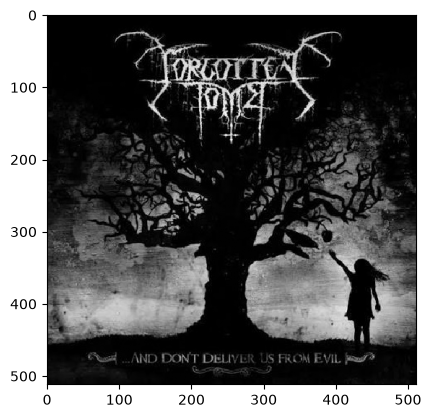

In [3]:
img = cv.imread('image.jpg', cv.IMREAD_GRAYSCALE)
plt.imshow(img, cmap = 'gray')

#### 1 ступень

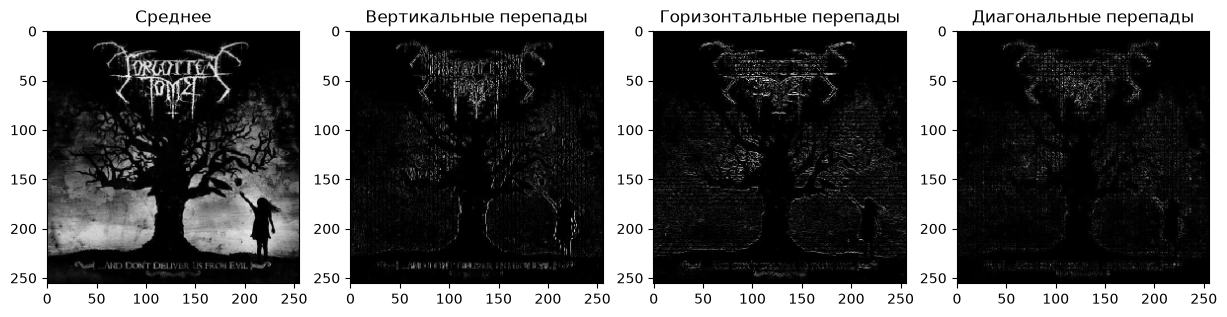

In [4]:
step1_A11, step1_A12, step1_A21, step1_A22 = haar_step(img)
show_4_imgs(step1_A11, step1_A12, step1_A21, step1_A22)

#### 2 ступень

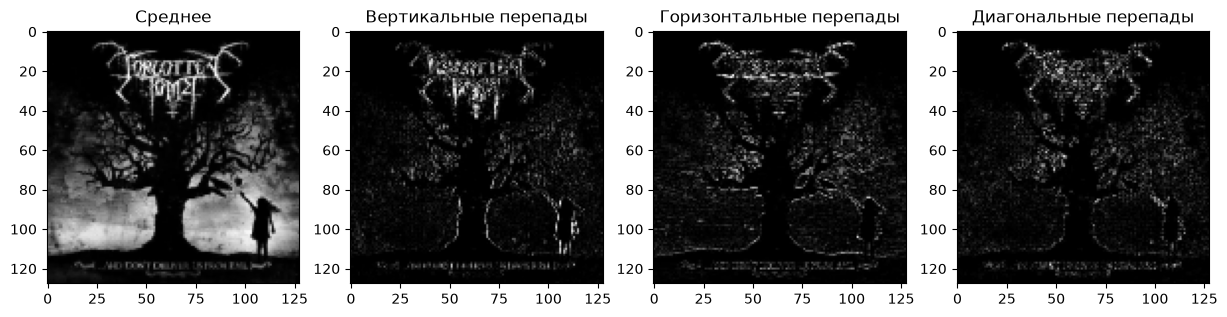

In [6]:
step2_A11, step2_A12, step2_A21, step2_A22 = haar_step(step1_A11)
show_4_imgs(step2_A11, step2_A12, step2_A21, step2_A22)

#### 3 ступень

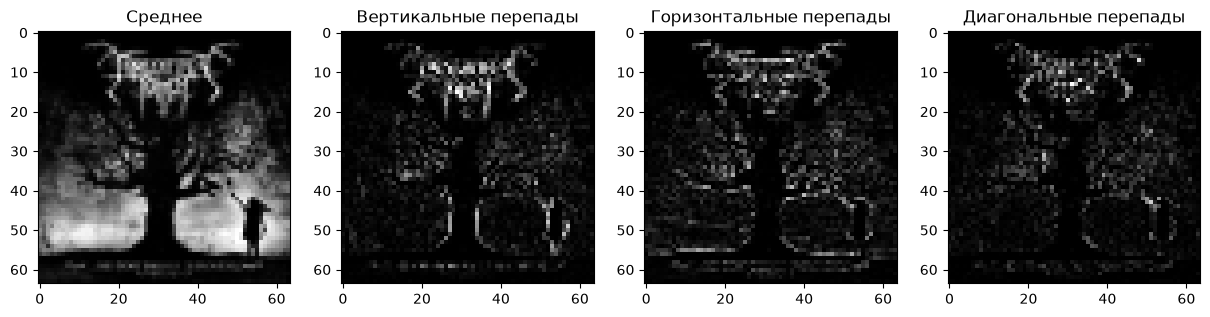

In [7]:
step3_A11, step3_A12, step3_A21, step3_A22 = haar_step(step2_A11)
show_4_imgs(step3_A11, step3_A12, step3_A21, step3_A22)